# Đồ án Phân tích Dữ liệu: Các Yếu tố Ảnh hưởng tới Điểm Thi Môn Toán (student-mat)

**Câu hỏi nghiên cứu chính:** Thời gian tự học (`studytime`), số buổi vắng (`absences`), hỗ trợ gia đình (`famsup`) và điểm quá trình ($G1, G2$) có mối liên hệ như thế nào với điểm thi cuối kỳ ($G3$)?

- **Dữ liệu sử dụng:**
  - Dữ liệu học sinh UCI: Môn Toán (`student-mat.csv`, 395 học sinh) là tập phân tích chính; Môn Tiếng Bồ Đào Nha (`student-por.csv`, 649 học sinh) dùng để kiểm chứng quy tắc cảnh báo sớm rủi ro trên học sinh mới (Strict Holdout, 275 học sinh độc lập).
  - Dữ liệu bối cảnh quốc tế: Bảng xếp hạng PISA cào từ Wikipedia và đối chiếu chéo với bảng báo cáo chính thức của OECD.
- **Quy trình xử lý (Pipeline):** `StudentDataProcessor.load_data → clean_data → analyze → export_results` (trong file `data_processor.py`, chạy tự động qua `main.py`).
- **Dữ liệu đầu ra:** `data/processed/cleaned_students.csv` (1044 dòng gồm cả 2 môn), `cleaned_students_mat.csv` (395 dòng), `cleaned_students_por.csv` (649 dòng), `pisa_clean.csv`, `summary.json`, và 3 biểu đồ trong thư mục `images/`.
- **Tác động phụ:** Khi chạy notebook này, hệ thống sẽ ghi đè và đồng bộ lại các file kết quả giống hệt như khi chạy `main.py` (`data/processed/*`, `images/*.png`). Không tốn lưu lượng mạng khi file thô và cache PISA đã tồn tại.
- **Hướng dẫn sử dụng:** Chạy tuần tự các ô code từ trên xuống dưới (chọn **Run All** hoặc bấm `Shift + Enter` từng ô). Các ô code dùng chung các biến (`proc`, `clean`, `res`), nên nếu nhảy cóc ô thì sẽ bị lỗi biến chưa định nghĩa (`NameError`). Nếu khởi động lại Kernel (Restart), hãy chạy lại từ Mục 2 trước khi chạy các phần sau.
- **Notebook vs `main.py`:** Cả hai đều gọi cùng class `StudentDataProcessor`; notebook cho phép chạy từng bước và quan sát trực quan kết quả từng giai đoạn, còn `main.py` chạy toàn bộ trong 1 lệnh và in log tóm tắt.

## 1. Nền tảng Python: 4 hàm xử lý logic + Cấu trúc dữ liệu

Khảo sát 4 hàm thuần túy (pure functions) và cấu trúc dữ liệu nền tảng:
- `convert_yes_no`: Chuẩn hoá chuỗi 'yes'/'no' thành 1/0, trả về `None` nếu gặp giá trị lạ (không tự ý đoán bừa).
- `calc_pass_fail`: Xác định đỗ/trượt (mặc định đỗ khi điểm $G3 \ge 10$).
- `classify_absences`: Phân loại mức độ vắng học thành 3 nhóm (`low`: 0–3, `medium`: 4–9, `high`: $\ge 10$).
- `calc_average_grade`: Tính trung bình cộng 3 kỳ $(G1 + G2 + G3) / 3$.
- Cấu trúc dữ liệu: `list[dict]` lưu học sinh mẫu, `dict` ánh xạ mô tả biến, `set()` tập giá trị duy nhất, `tuple` lưu hằng số ngưỡng cố định.

In [1]:
# Import các hằng số cấu hình, từ điển mô tả biến và 4 hàm logic từ module data_processor
from data_processor import (
    THRESHOLDS, ANOMALY_THRESHOLDS, VAR_DESCRIPTIONS, SAMPLE_STUDENTS,
    convert_yes_no, calc_pass_fail, classify_absences, calc_average_grade,
)

# 1. In các bộ ngưỡng cố định (khai báo tập trung ở đầu file, tránh magic numbers)
print('=== CÁC BỘ NGƯỠNG HẰNG SỐ CỦA HỆ THỐNG ===')
print('THRESHOLDS (PASS, G_WARN, ABS_MED, ABS_HIGH, FAIL_HIGH):', THRESHOLDS)
print('ANOMALY_THRESHOLDS (IQR_K, G1_DROP, G2_DROP, AGE_OUTLIER):', ANOMALY_THRESHOLDS)
print()

# 2. Kiểm tra từ điển mô tả biến
print("Mô tả biến 'famsup' (hỗ trợ gia đình):", VAR_DESCRIPTIONS['famsup'])
print()

# 3. Kiểm thử hàm convert_yes_no: chuẩn hoá khoảng trắng, chữ hoa/thường, và bắt lỗi giá trị lạ
print('=== KIỂM THỬ HÀM convert_yes_no ===')
print(" ' Yes ' ->", convert_yes_no(' Yes '))    # Trả về 1 (cắt khoảng trắng, chuyển chữ thường)
print(" 'no'     ->", convert_yes_no('no'))       # Trả về 0
print(" 'maybe'  ->", convert_yes_no('maybe'))    # Trả về None (không đoán bừa thành 0, bảo vệ tính toàn vẹn)
print()

# 4. Chạy thử nghiệm các hàm trên danh sách học sinh mẫu (SAMPLE_STUDENTS)
print('=== CHẠY THỬ TRÊN CÁC HỌC SINH MẪU (SAMPLE_STUDENTS) ===')
for s in SAMPLE_STUDENTS:
    hs_id = s['id']
    ket_qua = calc_pass_fail(s['G3'])                     # Đỗ hay trượt kỳ G3
    muc_vang = classify_absences(s['absences'])           # Phân loại mức độ vắng học
    dtb = round(calc_average_grade(s['G1'], s['G2'], s['G3']), 2)  # Điểm trung bình 3 kỳ
    co_internet = convert_yes_no(s['internet'])           # Mã hoá có/không internet thành 1/0
    print(f"Học sinh #{hs_id}: Điểm G3={s['G3']} ({ket_qua}) | Vắng {s['absences']} buổi ({muc_vang}) | ĐTB={dtb} | Internet={co_internet}")

/Users/chithien/code/Python-data-scraping/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


=== CÁC BỘ NGƯỠNG HẰNG SỐ CỦA HỆ THỐNG ===
THRESHOLDS (PASS, G_WARN, ABS_MED, ABS_HIGH, FAIL_HIGH): (10, 10, 4, 10, 2)
ANOMALY_THRESHOLDS (IQR_K, G1_DROP, G2_DROP, AGE_OUTLIER): (1.5, 8, 6, 20)

Mô tả biến 'famsup' (hỗ trợ gia đình): Family educational support (yes/no)

=== KIỂM THỬ HÀM convert_yes_no ===
 ' Yes ' -> 1
 'no'     -> 0
 'maybe'  -> None

=== CHẠY THỬ TRÊN CÁC HỌC SINH MẪU (SAMPLE_STUDENTS) ===
Học sinh #1: Điểm G3=6 (fail) | Vắng 6 buổi (medium) | ĐTB=5.67 | Internet=1
Học sinh #2: Điểm G3=6 (fail) | Vắng 4 buổi (medium) | ĐTB=5.33 | Internet=0
Học sinh #3: Điểm G3=10 (pass) | Vắng 10 buổi (high) | ĐTB=8.33 | Internet=1


## 2. Thu thập & Đọc dữ liệu (UCI zip, cào dữ liệu PISA)

- Tải file zip gốc từ kho UCI Machine Learning Repository (nếu chưa có trong `data/raw`).
- Cào bảng xếp hạng PISA từ trang Wikipedia về lưu vào `pisa_reference.csv` (cơ chế cache-first).
- Khởi tạo đối tượng `StudentDataProcessor` và nạp toàn bộ dữ liệu thô vào DataFrame bằng `load_data()`.

In [2]:
from pathlib import Path
from data_processor import StudentDataProcessor, fetch_uci_raw, scrape_pisa_table

RAW = Path('data/raw')

# 1. Tải và giải nén dữ liệu UCI (nếu đã có file sẵn thì tự động bỏ qua, không tải lại)
fetch_uci_raw(RAW)

# 2. Cào bảng dữ liệu PISA từ Wikipedia (sử dụng cache nếu file đã tồn tại)
pisa_raw = scrape_pisa_table(out_csv=RAW / 'pisa_reference.csv')
print('Số dòng dữ liệu PISA thô cào được:', len(pisa_raw))

# 3. Khởi tạo đối tượng xử lý trung tâm StudentDataProcessor
proc = StudentDataProcessor(
    {'mat': RAW / 'student-mat.csv', 'por': RAW / 'student-por.csv'},
    RAW / 'pisa_reference.csv',
    Path('data/processed'),
    Path('images'),
    oecd_raw=RAW / 'oecd_pisa2025_table_I1.csv',
)

# 4. Nạp dữ liệu thô dạng chuỗi gốc để kiểm soát chặt chẽ việc ép kiểu
df = proc.load_data()
print('Kích thước DataFrame sau khi nạp (load_data):', df.shape)
print('Số lượng học sinh theo từng môn:', df['subject'].value_counts().to_dict())

Số dòng dữ liệu PISA thô cào được: 2342
Kích thước DataFrame sau khi nạp (load_data): (1044, 34)
Số lượng học sinh theo từng môn: {'por': 649, 'mat': 395}


## 3. Làm sạch dữ liệu: Nhật ký kiểm tra + Gắn cờ bất thường (Gắn cờ, tuyệt đối không xoá)

Quy trình làm sạch tuân thủ 3 nguyên tắc bất di bất dịch:
1. **Không sửa đoán:** Giá trị lỗi chuyển thành `NaN` hoặc `None`, không đoán bừa.
2. **Không xoá dữ liệu bất thường:** Các điểm dị biệt được gắn cờ (Flags) True/False để phục vụ phân tích đa kịch bản.
3. **Minh bạch:** Toàn bộ biến động (ép kiểu, ngoài miền, trùng lặp, thiếu) đều ghi nhận vào `cleaning_log`.

In [3]:
import json
from data_processor import FLAG_COLS

# 1. Thực thi quy trình làm sạch 6 bước
clean = proc.clean_data()
log = proc.cleaning_log

# 2. Hiển thị tổng quan nhật ký làm sạch (cleaning_log)
print('=== NHẬT KÝ LÀM SẠCH (CLEANING LOG) ===')
print('Tổng số dòng vào/ra và các lỗi phát hiện:')
print({k: v for k, v in log.items() if isinstance(v, int)})
print('Tổng số ô ngoài miền hợp lệ (16 cột số):', sum(log['n_out_of_range'].values()),
      '| Tổng số giá trị dị biệt yes/no:', sum(log['n_invalid_yes_no'].values()))
print('Hàng rào ngoại lai vắng học (Tukey IQR fence) từng môn:', log['absence_outlier_fence'])
print()

# 3. Thống kê số lượng cờ bất thường trên cả 2 môn học (Toán và Tiếng Bồ Đào Nha)
print('=== THỐNG KÊ 6 CỜ BẤT THƯỜNG (ANOMALY FLAGS) ===')
print(clean.groupby('subject')[FLAG_COLS].sum().T)

=== NHẬT KÝ LÀM SẠCH (CLEANING LOG) ===
Tổng số dòng vào/ra và các lỗi phát hiện:
{'rows_in': 1044, 'n_cells_stripped': 0, 'n_duplicates_dropped': 0, 'n_missing_required_dropped': 0, 'rows_out': 1044}
Tổng số ô ngoài miền hợp lệ (16 cột số): 0 | Tổng số giá trị dị biệt yes/no: 0
Hàng rào ngoại lai vắng học (Tukey IQR fence) từng môn: {'mat': 20.0, 'por': 15.0}

=== THỐNG KÊ 6 CỜ BẤT THƯỜNG (ANOMALY FLAGS) ===
subject             mat  por
dropout_suspect      38   15
g2_zero              13    7
grade_drop            0    1
absence_outlier      15   21
age_outlier           5    9
inconsistent_grade    0    0


Số học sinh bị điểm G3 = 0: 38 | Số em có số buổi vắng = 0: 38 | Số em có điểm G2 = 0: 13

Thống kê mô tả nhóm G3 = 0 (Mean, Min, Max):
             G1         G2   G3  absences  failures
mean   7.526316   4.657895  0.0       0.0  0.921053
min    4.000000   0.000000  0.0       0.0  0.000000
max   12.000000  10.000000  0.0       0.0  3.000000


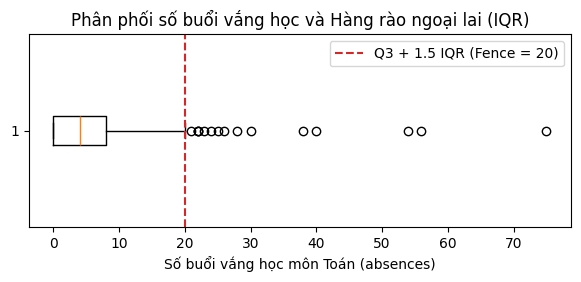

In [4]:
# 1. Phân tích chi tiết nhóm học sinh bị điểm 0 kỳ G3 ở môn Toán
mat = clean[clean['subject'] == 'mat']
zero = mat[mat['dropout_suspect']]
print('Số học sinh bị điểm G3 = 0:', len(zero),
      '| Số em có số buổi vắng = 0:', int((zero['absences'] == 0).sum()),
      '| Số em có điểm G2 = 0:', int((zero['G2'] == 0).sum()))

# 2. Bảng thống kê tóm tắt điểm số và chuyên cần của nhóm học sinh điểm 0
print('\nThống kê mô tả nhóm G3 = 0 (Mean, Min, Max):')
print(zero[['G1', 'G2', 'G3', 'absences', 'failures']].describe().loc[['mean', 'min', 'max']])

# 3. Vẽ biểu đồ hộp (Boxplot) số buổi vắng học kèm đường hàng rào ngoại lai IQR fence = 20
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.boxplot(mat['absences'], vert=False)
ax.axvline(log['absence_outlier_fence']['mat'], color='C3', ls='--', label='Q3 + 1.5 IQR (Fence = 20)')
ax.set_xlabel('Số buổi vắng học môn Toán (absences)')
ax.set_title('Phân phối số buổi vắng học và Hàng rào ngoại lai (IQR)')
ax.legend()
plt.show()

## 4. Phân tích khám phá (EDA): Thống kê mô tả Mean/Std theo nhóm (Toàn bộ vs. Loại trừ điểm 0)

So sánh điểm số $G3$ trung bình giữa 2 phạm vi (scopes):
- `all`: Toàn bộ 395 học sinh môn Toán (bao gồm cả 38 em bị điểm 0).
- `exclude_dropout`: 357 học sinh sau khi loại trừ 38 em nghi vấn bỏ thi ($G3 = 0$).

In [5]:
# Chạy hàm phân tích tổng hợp EDA
res = proc.analyze()

# So sánh chi tiết từng biến nhân khẩu học và học tập giữa 2 nhóm phạm vi
for scope in ['all', 'exclude_dropout']:
    s = res['scopes'][scope]
    ten_pham_vi = 'Toàn bộ học sinh (all)' if scope == 'all' else 'Loại trừ điểm 0 (exclude_dropout)'
    print(f"\n### {ten_pham_vi}: n={s['n']} tỉ lệ đỗ={s['pass_rate']:.2%} (Đỗ: {s['n_pass']} / Trượt: {s['n_fail']})")
    for key in ['by_studytime', 'by_absence_level', 'by_failures', 'by_internet',
                'by_famsup', 'by_schoolsup', 'by_paid', 'by_risk_group']:
        print(f"  {key}: " + ', '.join(f"{g}={v['mean']}±{v['std']} (n={v['n']})" for g, v in s[key].items()))


### Toàn bộ học sinh (all): n=395 tỉ lệ đỗ=67.09% (Đỗ: 265 / Trượt: 130)
  by_studytime: 1=10.05±4.96 (n=105), 2=10.17±4.22 (n=198), 3=11.4±4.64 (n=65), 4=11.26±5.28 (n=27)
  by_absence_level: high=10.37±3.2 (n=83), low=9.82±5.61 (n=191), medium=11.38±3.25 (n=121)
  by_failures: 0=11.25±4.17 (n=312), 1=8.12±4.71 (n=50), 2=6.24±4.84 (n=17), 3=5.69±4.19 (n=16)
  by_internet: no=9.41±4.49 (n=66), yes=10.62±4.58 (n=329)
  by_famsup: no=10.64±4.64 (n=153), yes=10.27±4.55 (n=242)
  by_schoolsup: no=10.56±4.77 (n=344), yes=9.43±2.87 (n=51)
  by_paid: no=9.99±5.13 (n=214), yes=10.92±3.79 (n=181)
  by_risk_group: high=6.22±3.85 (n=149), low=13.57±2.51 (n=169), medium=11.6±2.83 (n=77)

### Loại trừ điểm 0 (exclude_dropout): n=357 tỉ lệ đỗ=74.23% (Đỗ: 265 / Trượt: 92)
  by_studytime: 1=11.47±3.41 (n=92), 2=11.07±3.07 (n=182), 3=12.56±2.99 (n=59), 4=12.67±3.6 (n=24)
  by_absence_level: high=10.37±3.2 (n=83), low=12.26±3.04 (n=153), medium=11.38±3.25 (n=121)
  by_failures: 0=11.94±3.19 (n=294), 1=

## 5. Trực quan hoá dữ liệu (3 biểu đồ bắt buộc)

Hiển thị 3 biểu đồ trực quan được tự động xuất ra thư mục `images/`:
1. `01_bar_studytime_internet.png`: Điểm $G3$ trung bình theo Thời gian tự học kết hợp Internet (kèm khoảng tin cậy 95% CI).
2. `02_hist_g3.png`: Phân phối tần số điểm cuối kỳ $G3$, làm nổi bật 38 học sinh điểm 0 màu đỏ.
3. `03_heatmap_corr.png`: Ma trận tương quan Pearson giữa các biến chính (đã che nửa trên đối xứng).

=== BIỂU ĐỒ: 01_bar_studytime_internet.png ===


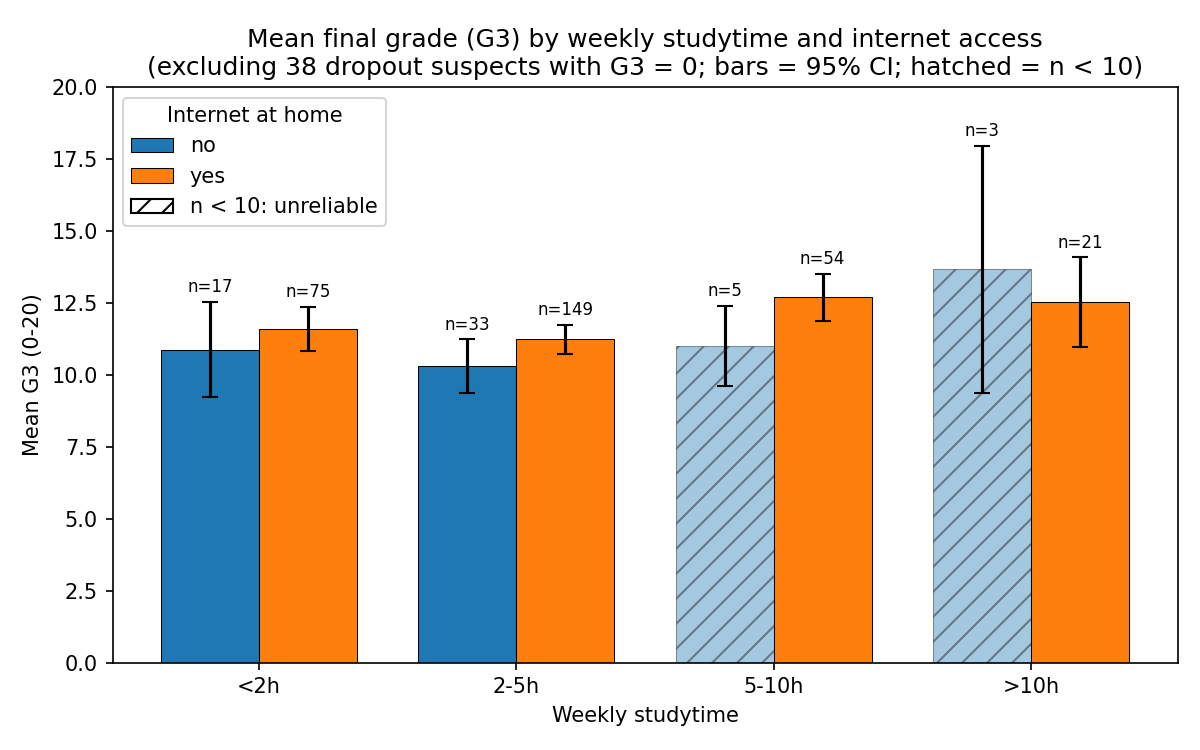

=== BIỂU ĐỒ: 02_hist_g3.png ===


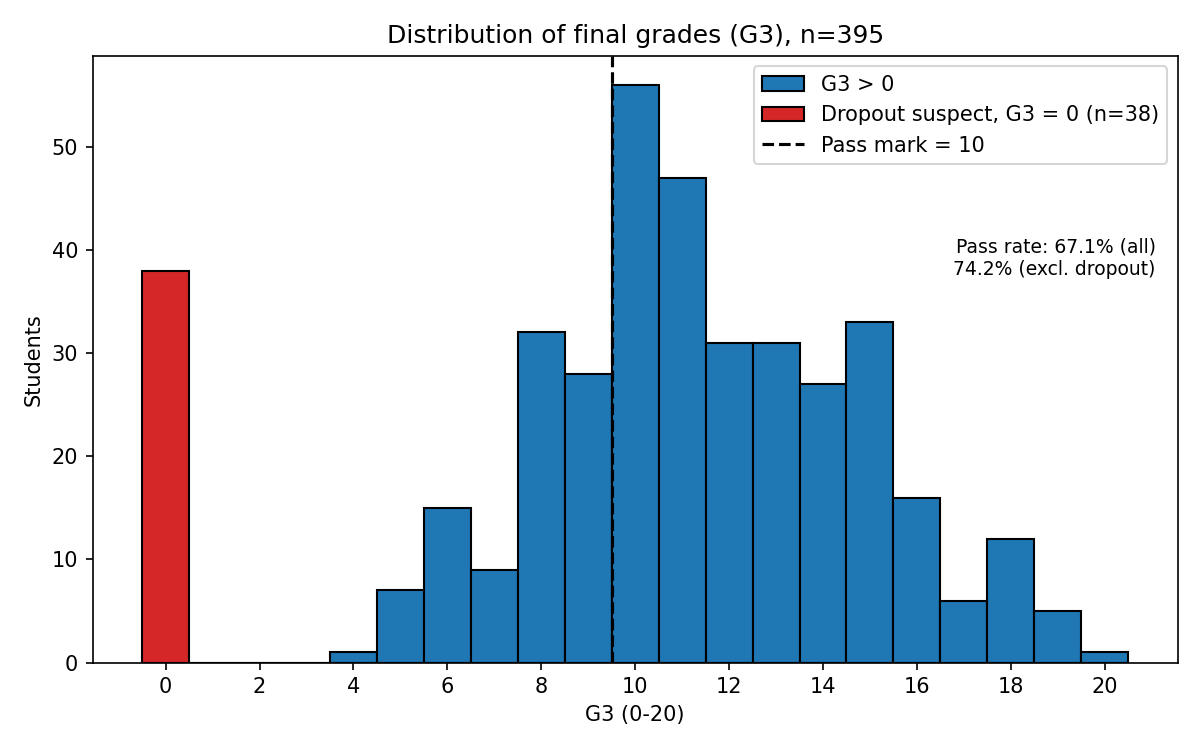

=== BIỂU ĐỒ: 03_heatmap_corr.png ===


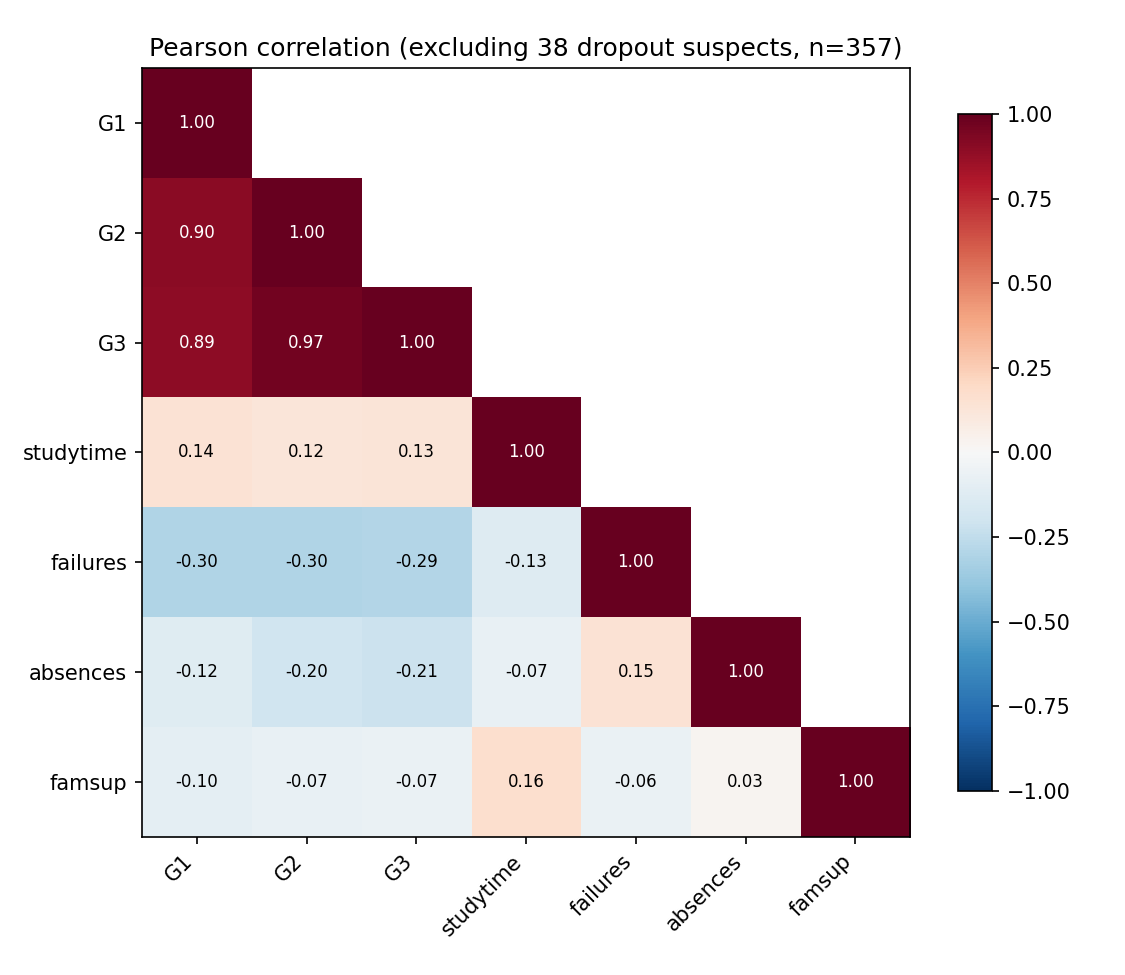

In [6]:
from IPython.display import Image, display

# Hiển thị trực tiếp 3 biểu đồ đã vẽ và lưu trong thư mục images/
for name in ['01_bar_studytime_internet.png', '02_hist_g3.png', '03_heatmap_corr.png']:
    print(f'=== BIỂU ĐỒ: {name} ===')
    display(Image(f'images/{name}'))

## 6. Phân tích tương quan giữa G1, G2, G3 (Ảnh hưởng che mắt của nhóm học sinh điểm 0)

- Khi tính trên toàn bộ 395 em (`all`), sự hiện diện của 38 em điểm 0 (vừa có $G3=0$ vừa có $absences=0$) làm tương quan giữa vắng học và điểm số bị méo mó thành số dương ($+0.034$, tức nghỉ học nhiều lại điểm cao hơn - phi lý).
- Khi loại trừ nhóm điểm 0 (`exclude_dropout`), tương quan lập tức quay về âm chuẩn xác ($-0.213$, cúp học làm tụt điểm).

In [7]:
import pandas as pd

# 1. So sánh tương quan giữa G1, G2 và G3 giữa 2 phạm vi dữ liệu
print('=== TƯƠNG QUAN G1 - G2 - G3 ===')
for scope in ['all', 'exclude_dropout']:
    ten_scope = 'Toàn bộ (all):' if scope == 'all' else 'Loại trừ điểm 0 (exclude_dropout):'
    print(ten_scope, res['scopes'][scope]['corr_G1_G2_G3'])
print()

# 2. Ma trận tương quan đầy đủ giữa các biến trên tập exclude_dropout (làm tròn 2 chữ số thập phân)
print('=== MA TRẬN TƯƠNG QUAN ĐẦY ĐỦ (EXCLUDE_DROPOUT) ===')
print(pd.DataFrame(res['scopes']['exclude_dropout']['corr_full']).round(2).to_string())

=== TƯƠNG QUAN G1 - G2 - G3 ===
Toàn bộ (all): {'G1_G2': 0.852, 'G1_G3': 0.801, 'G2_G3': 0.905}
Loại trừ điểm 0 (exclude_dropout): {'G1_G2': 0.902, 'G1_G3': 0.892, 'G2_G3': 0.966}

=== MA TRẬN TƯƠNG QUAN ĐẦY ĐỦ (EXCLUDE_DROPOUT) ===
              G1    G2    G3  studytime  failures  absences  famsup_bin
G1          1.00  0.90  0.89       0.14     -0.30     -0.12       -0.10
G2          0.90  1.00  0.97       0.12     -0.30     -0.20       -0.07
G3          0.89  0.97  1.00       0.13     -0.29     -0.21       -0.07
studytime   0.14  0.12  0.13       1.00     -0.13     -0.08        0.16
failures   -0.30 -0.30 -0.29      -0.13      1.00      0.15       -0.06
absences   -0.12 -0.20 -0.21      -0.08      0.15      1.00        0.02
famsup_bin -0.10 -0.07 -0.07       0.16     -0.06      0.02        1.00


## 6b. Kiểm định giả thuyết thống kê (Welch t-test, One-way ANOVA, hiệu chỉnh Holm) + Kiểm định tương quan Pearson

**Cách đọc bảng kiểm định:**
- `p`: Giá trị $p$-value thô của từng kiểm định riêng lẻ.
- `p_holm`: Giá trị $p$-value sau khi hiệu chỉnh đa kiểm định Holm-Bonferroni (kiểm soát sai số FWER cho cả 7 kiểm định). Một biến chỉ được coi là **có ý nghĩa thống kê thực sự** nếu $p_{holm} < 0.05$ (cột `significant = True`).
- `eta2` ($\eta^2$): Tỷ lệ phương sai của điểm $G3$ được giải thích bởi biến đó (chỉ áp dụng cho các hàng ANOVA).
- Trong bảng tương quan Pearson: `r` là hướng và độ mạnh tương quan (từ -1 đến +1), `ci95` là khoảng tin cậy 95% của hệ số tương quan.

In [8]:
# 1. Bảng kết quả kiểm định nhóm (Welch t-test cho biến 2 mức và ANOVA cho biến nhiều mức) kèm hiệu chỉnh Holm
print('=== KẾT QUẢ KIỂM ĐỊNH GIẢ THUYẾT (NHÓM BIẾN) ===')
tests = pd.DataFrame(res['scopes']['exclude_dropout']['group_tests']).T
print(tests[['test', 'stat', 'p', 'p_holm', 'diff', 'ci95', 'eta2', 'significant']].to_string())
print()

# 2. Bảng kết quả kiểm định ý nghĩa thống kê của các hệ số tương quan Pearson với điểm G3
print('=== KIỂM ĐỊNH TƯƠNG QUAN PEARSON VỚI ĐIỂM G3 ===')
print(pd.DataFrame(res['scopes']['exclude_dropout']['corr_tests']).T.to_string())

=== KẾT QUẢ KIỂM ĐỊNH GIẢ THUYẾT (NHÓM BIẾN) ===
                        test   stat         p    p_holm  diff            ci95   eta2 significant
internet        Welch t-test   2.25    0.0268    0.0804  0.98    [0.11, 1.84]    NaN       False
famsup          Welch t-test  -1.28     0.202     0.404 -0.45   [-1.13, 0.24]    NaN       False
schoolsup       Welch t-test  -5.46  0.000001  0.000003 -2.21  [-3.02, -1.41]    NaN        True
paid            Welch t-test  -0.55     0.585     0.585 -0.19   [-0.86, 0.48]    NaN       False
studytime      one-way ANOVA   4.38   0.00482    0.0193   NaN             NaN  0.036        True
absence_level  one-way ANOVA   9.85  0.000069  0.000343   NaN             NaN  0.053        True
failures       one-way ANOVA  17.19       0.0  0.000001   NaN             NaN  0.089        True

=== KIỂM ĐỊNH TƯƠNG QUAN PEARSON VỚI ĐIỂM G3 ===
                r         p              ci95
G1          0.892       0.0    [0.868, 0.911]
G2          0.966       0.0    [0

## 7. Đánh giá quy tắc cảnh báo sớm rủi ro (Không sử dụng G3 trong quy tắc): In-sample vs. Holdout (Môn Tiếng Bồ Đào Nha)

**Nguyên tắc thiết kế quy tắc:**
- Phân tầng học sinh thành 3 mức: `high` (nguy cơ cao), `medium` (trung bình), `low` (an toàn).
- Tuyệt đối **không dùng điểm cuối kỳ $G3$** trong quy tắc để tránh rò rỉ dữ liệu (No Data Leakage).
- `recall`: Tỉ lệ học sinh trượt môn thực tế mà quy tắc bắt trúng vào nhóm `high` (càng cao càng tốt, tránh bỏ sót).
- `precision`: Tỉ lệ học sinh bị xếp vào nhóm `high` mà thực sự trượt môn cuối kỳ.
- `all` và `exclude_dropout` được đo trên môn Toán (tập dữ liệu dùng để chọn ngưỡng - in-sample).
- `holdout_por` là toàn bộ môn Tiếng Bồ Đào Nha.
- `holdout_por_only` chỉ giữ lại **275 học sinh môn Tiếng Bồ Đào Nha hoàn toàn độc lập** (không trùng lặp với môn Toán) - đây là thước đo khách quan và trung thực nhất về khả năng tổng quát hoá của quy tắc.

In [9]:
# Thu thập và định dạng bảng đánh giá hiệu năng quy tắc cảnh báo rủi ro trên các tập dữ liệu
rows = []
for scope, r in res['risk_eval'].items():
    h = r['high']
    rows.append({
        'scope': scope,
        'n': r['n'],
        'fail_rate': f"{r['fail_rate']:.1%}",
        'recall': f"{h['recall']:.1%}",
        'precision': f"{h['precision']:.1%}",
        **{f'fail_rate_{g}': f"{v:.1%}" for g, v in r['fail_rate_by_group'].items()}
    })

print('=== ĐÁNH GIÁ QUY TẮC CẢNH BÁO RỦI RO (RISK RULE) ===')
print(pd.DataFrame(rows).to_string(index=False))

=== ĐÁNH GIÁ QUY TẮC CẢNH BÁO RỦI RO (RISK RULE) ===
           scope   n fail_rate recall precision fail_rate_low fail_rate_medium fail_rate_high
             all 395     32.9%  93.8%     81.9%          1.2%             7.8%          81.9%
 exclude_dropout 357     25.8%  93.5%     76.1%          1.2%             5.3%          76.1%
     holdout_por 649     15.4%  90.0%     59.2%          0.5%             7.9%          59.2%
holdout_por_only 275     25.4%  91.4%     66.0%          0.8%             9.8%          66.0%


## 8. Bối cảnh quốc tế qua dữ liệu PISA (Cào dữ liệu web) + Đối chiếu chéo với OECD

- Đặt kết quả điểm môn Toán của học sinh Bồ Đào Nha vào bức tranh giáo dục quốc tế qua các kỳ thi PISA 2006, 2015, 2025.
- Thực hiện kiểm chứng chéo (Sanity check) giữa dữ liệu cào từ Wikipedia với bảng báo cáo chính thức của OECD (Table I.1) để đảm bảo tính xác thực của dữ liệu thu thập.

In [10]:
pisa = proc.pisa_clean
print('Kích thước dữ liệu PISA sạch:', pisa.shape)
print('Các năm có dữ liệu theo môn và nguồn:', pisa.groupby(['source', 'subject'])['year'].unique().to_dict())
print()

# Bảng điểm PISA của Bồ Đào Nha qua các năm so với trung bình các nước OECD
print('=== BỐI CẢNH ĐIỂM PISA CỦA BỒ ĐÀO NHA ===')
ctx = pd.DataFrame({(subj, int(y)): v for subj, years in res['pisa_context'].items()
                    for y, v in years.items()}).T
print(ctx.to_string())
print()

# Kết quả đối chiếu chéo giữa số liệu Wikipedia và báo cáo gốc của OECD
print('=== ĐỐI CHIẾU CHÉO WIKIPEDIA VS BÁO CÁO OECD ===')
check = res['pisa_oecd_check']
for year in [k for k in check if k.isdigit()]:
    c = check[year]
    print(f"Đối chiếu năm {year}: {c['n_within_tolerance']}/{c['n_compared']} quốc gia khớp trong ngưỡng sai số ±{c['tolerance']} điểm. Lệch: {c['mismatches']}")
print('Các nước thiếu trên Wikipedia:', check['missing_in_wikipedia'])

Kích thước dữ liệu PISA sạch: (1662, 6)
Các năm có dữ liệu theo môn và nguồn: {('comparison', 'mathematics'): array([2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022]), ('comparison', 'reading'): array([2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022]), ('comparison', 'science'): array([2006, 2009, 2012, 2015, 2018, 2022]), ('summary', 'mathematics'): array([2025]), ('summary', 'reading'): array([2025]), ('summary', 'science'): array([2025])}

=== BỐI CẢNH ĐIỂM PISA CỦA BỒ ĐÀO NHA ===
                  portugal  portugal_rank  oecd_average
mathematics 2000       454             23           492
            2003       466             30           499
            2006       466             35           494
            2009       487             31           495
            2012       487             29           494
            2015       492             29           490
            2018       492             28           489
            2022       472             29           472
         

In [11]:
# Xuất dữ liệu đã làm sạch và file tóm tắt chỉ số tổng hợp
cleaned_csv, summary_json = proc.export_results()
print('=== XUẤT KẾT QUẢ THÀNH CÔNG ===')
print('File CSV dữ liệu sạch:', cleaned_csv)
print('File JSON tóm tắt chỉ số:', summary_json)

=== XUẤT KẾT QUẢ THÀNH CÔNG ===
File CSV dữ liệu sạch: data/processed/cleaned_students.csv
File JSON tóm tắt chỉ số: data/processed/summary.json


## 9. Tổng kết phát hiện (Insights) & Giới hạn nghiên cứu (Limitations)

### 📌 Các phát hiện chính (Phân tích trên 357 học sinh môn Toán sau khi loại trừ 38 em điểm 0):
1. **Chất lượng dữ liệu & Bước làm sạch:** Dữ liệu thô từ UCI rất sạch về mặt cú pháp (0 lỗi ngoài miền, 0 lỗi yes/no, 0 dòng trùng). Thách thức thực sự nằm ở mặt ngữ nghĩa: **38 học sinh có $G3 = 0$**, tất cả đều có số buổi vắng bằng 0 và điểm $G1$ trung bình đạt 7.5 (dấu hiệu bỏ thi). Việc gắn cờ (`dropout_suspect`) thay vì để yên giúp khôi phục mối tương quan thực sự giữa vắng học và điểm số từ $+0.034$ về đúng $-0.213$.
2. **Điểm quá trình giữ vai trò quyết định:** Điểm giữa kỳ $G2$ tương quan cực mạnh với $G3$ ($r = +0.966$), điểm kỳ 1 $G1$ tương quan $+0.892$.
3. **Số lần trượt môn cũ và Vắng học kéo tụt điểm mạnh nhất:** Số lần trượt $failures$ tương quan âm rõ rệt ($r = -0.294$, ANOVA $\eta^2 = 0.089$), số buổi vắng $absences$ kéo điểm xuống ($r = -0.213$, $\eta^2 = 0.053$); cả hai đều có ý nghĩa thống kê vững chắc sau hiệu chỉnh Holm ($p_{holm} < 0.001$).
4. **Thời gian tự học có tác động tích cực nhưng khiêm tốn:** Có ý nghĩa sau Holm ($p_{holm} = 0.019$), tuy nhiên chỉ giải thích được 3.6% phương sai điểm số ($\eta^2 = 0.036$).
5. **Internet và Hỗ trợ gia đình không có tác động độc lập:** Học sinh có internet đạt điểm cao hơn khoảng 1 điểm, nhưng sự khác biệt này **không có ý nghĩa thống kê sau hiệu chỉnh Holm** ($p_{holm} = 0.080$); hỗ trợ gia đình (`famsup`) cũng không cho thấy tác động rõ rệt ($p_{holm} = 0.404$).
6. **Quy tắc cảnh báo sớm rủi ro (Không dùng G3):** Nhóm `high` bắt trúng **93.8%** học sinh trượt ở môn Toán (độ chính xác 81.9%). Khi kiểm chứng độc lập ngoài mẫu trên 275 học sinh môn Tiếng Bồ Đào Nha chưa từng thấy (Strict Holdout), quy tắc vẫn duy trì **Recall 91.4%** và Precision 66.0%.

---

### ⚠️ Giới hạn nghiên cứu (Limitations):
- **Phạm vi mẫu:** Dữ liệu thu thập từ 2 trường cấp 3 tại Bồ Đào Nha trong năm học 2005–2006, là dữ liệu cắt ngang (Cross-sectional) nên chỉ phản ánh mối liên hệ tương quan chứ không khẳng định quan hệ nhân quả.
- **Phương thức đo lường:** Thời gian tự học và số buổi vắng là số liệu tự khai báo hoặc báo cáo từ trường theo nhóm mức độ.
- **Nhóm mẫu nhỏ:** Một số phân nhóm có cỡ mẫu quá nhỏ (ví dụ học sinh học >10h/tuần mà không có internet chỉ có 3 em) dẫn đến ước lượng thống kê kém ổn định.
- **Dữ liệu PISA:** Chỉ đóng vai trò cung cấp bối cảnh trình độ giáo dục cấp quốc gia, không liên kết trực tiếp với từng cá nhân học sinh trong tập dữ liệu.